In [1]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import fractional_matrix_power
from numpy import array, diag, dot, maximum, empty, repeat, ones, sum
from numpy.linalg import inv
import scipy as sp
import scipy.stats as sps
import scipy.io as spio
import astra
from venv import create
import pylops
from scipy import sparse
from scipy.ndimage import convolve
import scipy.special as spe
import requests
import h5py
from trips.utilities.io import *
from trips.utilities.operators import *
from trips.utilities.helpers import *
from trips.solvers.GKS import *
from trips.solvers.MMGKS import *


import sys
sys.path.append("../")


from voxelgrad import VoxelDynamicTomoOperator

import jlinops

from msolver import VanillaGKS
from msolver import MMGKS
from msolver import IASGKS

from voxelgrad import build_spatiotemporal_neumann2d

from voxelgrad import CGWeightedVoxelGradPinvGPUOperator


from PIL import Image


/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


# Set up problem

In [2]:
N_ITER = 50

In [3]:
(F, d, Aseq, B, nx, ny, nt) = generate_emoji(dataset = 30)

data already downloaded.


In [4]:
which_times = [2*(1 -1), 2*(4 -1), 2*(8 -1), 2*(11 -1), 2*(16 -1)]
loading_which_labels = ["01", "04", "08", "11", "15"]
how_many = len(which_times)
# Load all images
photos = []
for label in loading_which_labels:
    image_path = f"frame{label}c.jpg"
    image = Image.open(image_path)
    image_array = np.array(image)
    photos.append(image_array)

In [5]:
how_many = 5
voxel_shape = (nx, ny, how_many)
A = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in which_times ], voxel_shape)
b = np.hstack([ B[j] for j in which_times ] ) 
L = build_spatiotemporal_neumann2d(voxel_shape)
#NOISE_VAR = 0.0001
NOISE_VAR = 0.1*0.4

np.random.seed(0)
#b_noisy = b + np.sqrt(NOISE_VAR)*np.random.normal(size=len(b))
b_noisy = b.copy()

# Individual L2 reconstructions?

In [59]:
vgks_recons = []
for j in range(5):
    A = Aseq[which_times[j]]
    btrunc = B[which_times[j]]
    L = jlinops.Neumann2D((nx, ny))

    v_gks_solver = VanillaGKS(A, L, btrunc, noise_var=NOISE_VAR)
    vdata = v_gks_solver.solve(n_iter=N_ITER, init_dim=5)
    vgks_recons.append(vdata)

20008.702460316348
29709.67224755189
32206.22749006488
32864.62989977501


32088.504347183592
31365.647146141113
30723.59255798709
30372.32097404902
30155.26425544072
30006.52257549673
29944.10295626849
29933.488748688957
29986.883113383185
30075.76653834323
30192.72608107304
30325.349486871954
30456.054411295878
30564.04578211827
30652.662026292
30721.847319833534
30780.342895471258
30820.55263600641
30843.713040971987
30863.605259368742
30875.786400502308
30881.29259830218
30884.8059153811
30884.65966838056
30885.856431741428
30885.259664441026
30882.479786482596
30881.722210414657
30881.32673515776
30882.028485898132
30882.12802478956
30880.313721901344
30878.801007203125
30876.87070200561
30875.081847544287
30874.07707839091
30872.779415502293
30872.13588552922
30871.702355812253
30870.820665222735
30870.617829227434
30870.17165135414
30868.917706995802
30867.22071978771
30864.9137392015
30863.10003221919


20018.178392204765
29258.601405717498
31508.954979484806
31584.832569223792
30537.402035777337
29768.831951628075
29218.581605492705
28934.42979904575
28779.19936589033
28696.568129645886
28677.79228422008
28693.09986845747
28750.54125650611
28828.5258125565
28927.804422344834
29041.245781177517
29165.652527737995
29269.14778355066
29347.123865715344
29406.11401635754
29455.665071011357
29487.592493786426
29503.85116845478
29516.93081801874
29525.951587681004
29532.32747790549
29536.449136117695
29536.833048773817
29537.983921094215
29537.20082476198
29534.369509721666
29532.37510387469
29530.279709212064
29530.08512467535
29530.419502598397
29529.7898404431
29529.981108411586
29529.62443721481
29529.042366330705
29528.95545789645
29528.23881862459
29527.768822403188
29527.247979127846
29526.42436039089
29526.48910438554
29526.22706017999
29525.159226819764
29523.547669560525
29521.068630810827
29518.665112815877


17549.769766336445
25681.09392647888
27284.076919996718
27095.62498345405
26024.195047951107
25347.938210433487
24865.62063265786
24642.44934164771
24563.551836497292
24578.619460355076
24632.46766946462
24720.95887662668
24822.73873049845
24929.54439705123
25030.54739763237
25121.831363353514
25199.551022294207
25263.55701228568
25304.549450402992
25333.473165283478
25353.053515906482
25361.547204762184
25365.518684338753
25369.281911604878
25372.275237788403
25374.50215109167
25379.713612983414
25386.06170996368
25391.826804427248
25396.866828206137
25399.20806691369
25400.258820963827
25400.085708200328
25398.47160207932
25396.89303180195
25394.889783215644
25393.12715223673
25391.938059889486
25391.20814165418
25390.60789863271
25390.492748695186
25391.038703161485
25391.305204825432
25391.562794380847
25391.922474909385
25391.7873783525
25391.58586719793
25391.37536816426
25391.07929306308
25390.87444584061


17678.375313208013
25472.29166980089
26974.10672691286
26610.573845308336
25478.582749748883
24797.2352518055
24330.302535105497
24122.99352327376
24053.600673174285
24077.238640843425
24137.517180973515
24230.322554424285
24332.484491864296
24436.083658151863
24529.32560299553
24611.541010078538
24680.279269254002
24736.48197666981
24773.677100358742
24798.513487756823
24816.00947466714
24825.068751064187
24829.35163143515
24832.740603470902
24835.727580411996
24837.338368187502
24841.775796853497
24847.018604085293
24851.984774651057
24856.768861693326
24859.320842385263
24861.10683486201
24861.628527371322
24860.62297747357
24859.26482027472
24857.319926880733
24855.615801389158
24854.553737846094
24854.029906463915
24853.46915942553
24853.25215334192
24853.600033336217
24853.59290941491
24853.67534013606
24853.906652489426
24853.87089329925
24853.952815942383
24854.20408401275
24854.351753073825
24854.340315443616


19235.009884837076
28267.536620699702
30469.387975781803
30499.597667170172
29261.59728978223
28410.31746137963
27765.770152632707
27440.913158388506
27294.467647014284
27236.595441523652
27248.353362187023
27299.603382654375
27377.006132375027
27468.050097191
27569.592535856893
27680.4094375271
27775.600669682426
27855.28606138448
27917.83228775476
27960.808300384586
27995.725782413327
28015.926242824844
28023.23590960775
28027.696380111956
28027.112391551153
28024.044755615672
28020.024612802557
28013.89621380002
28009.891241415367
28006.073028243984
28003.880880122248
28006.724501221677
28011.567677591112
28017.16999313601
28021.7113839989
28023.44979456683
28023.8287940519
28021.94972247482
28019.752827853303
28018.31145449281
28016.928350820646
28016.740058273597
28016.582397677565
28015.86137067497
28015.761696019414
28015.648104602973
28015.601587462737
28015.272122577626
28014.00989053903
28012.779819835592


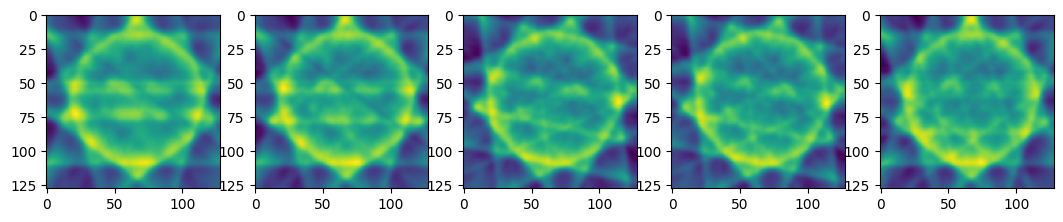

In [60]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow( vgks_recons[j]["x"].reshape((nx,ny)))

plt.show()

# Joint L2 reconstructions?

In [61]:
A = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in which_times ], voxel_shape)
L = build_spatiotemporal_neumann2d(voxel_shape)

In [62]:
v_gks_solver = VanillaGKS(A, L, b_noisy, noise_var=NOISE_VAR)

In [63]:
vdata = v_gks_solver.solve(n_iter=N_ITER, init_dim=5)

4309.838960244809


7321.961146437414
8746.537731417979
10125.006239993583
11350.880162922545
12207.535628415053
12973.426028776223
13555.387180796912
13856.844739594544
14045.284376393332
14132.957547552078
14164.645755978154
14202.895737572444
14252.225656364175
14285.240018540204
14279.664977892156
14233.849076883178
14179.049105849643
14165.402200329052
14210.710035500553
14315.216816564962
14404.725487727213
14439.707972021519
14427.072269590006
14395.408938725375
14375.508673061793
14376.208958249174
14384.233400419062
14386.277304990599
14379.861156592498
14370.315214285687
14365.30541313858
14365.365497952043
14368.416163485575
14372.60241498436
14378.422312052106
14385.546767060365
14391.544692840362
14394.347203809177
14393.41436370281
14390.319278703855
14387.042697906656
14384.420495188779
14382.593937414294
14381.550949654113
14381.447371636974
14382.342016628068
14383.592025017526
14384.545978179962
14384.843373219886


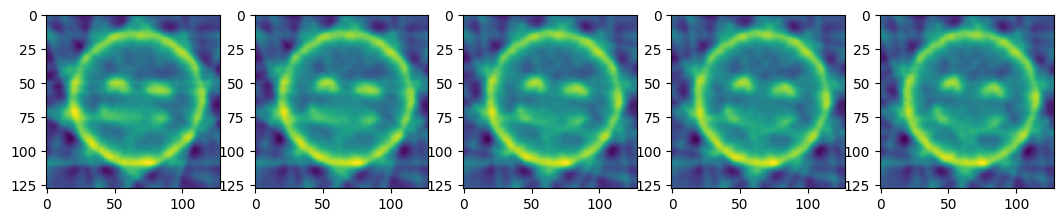

In [64]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(vdata["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

# SGKS individualls

In [65]:

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-5,
}


In [66]:
sgks_recons = []
for j in range(5):
    A = Aseq[which_times[j]]
    btrunc = B[which_times[j]]
    L = jlinops.Neumann2D((nx, ny))

    mm_gks_solver = MMGKS(A, L, btrunc, noise_var=NOISE_VAR)
    mm_gks_data = mm_gks_solver.solve(n_iter=N_ITER, init_dim=5, weight_params=mm_weight_params)
    sgks_recons.append(mm_gks_data)

203991.08815286364
48.61978967080058
57.191131503584806
61.47295678698819
64.92716649411425


67.31281916962668
68.93864436740434
70.30349786793408
71.18648391703823
71.93409353795892
72.45356927063229
72.8500126101732
73.08315746284747
73.21902212034635
73.37656333207629
73.47846436608542
73.60773687103725
73.70401283377919
73.80875465475015
73.91767908442776
74.03331369015929
74.14980619801987
74.26793921064112
74.39944093816662
74.51208467881864
74.60955756456872
74.70006107993306
74.75706572450144
74.79854189527204
74.83315398210605
74.86508908154248
74.88127266178495
74.89404691784824
74.90340516997885
74.9071387411449
74.91103368412973
74.91445492652353
74.9163503056176
74.9171761963002
74.91710431478289
74.91792044830666
74.92879582556009
74.9743521416269
75.05743826835247
75.16829969806675
75.28746777414713
75.42042754820811
75.53548924975372
75.62303665988064
75.67770086038682


249969.57408703933
50.01883083168046
56.889346003650274
60.96369329158224
63.74183591191499
65.94858224718182
67.60504687756325
68.75167704009004
69.5985299884963
70.21329095036079
70.66698766409964
70.9068637811796
71.11990253107744
71.27450273891284
71.42516568867876
71.56815786124497
71.74628750614781
71.87450918397055
72.00337102063851
72.09605734875227
72.22754013902451
72.3805176516713
72.5440665506626
72.67085400192104
72.82303172958798
72.9625873727795
73.05637420421182
73.13937424190574
73.19484345737655
73.23073680410384
73.257303267478
73.27036686144659
73.27898077751564
73.28726087772988
73.2967801819344
73.30364610239013
73.30873438709348
73.31356302452738
73.31832084642657
73.32108619151413
73.32352160961165
73.32399054889014
73.33215723828617
73.35500401068498
73.40172132381791
73.49261779812407
73.58389297456876
73.67532825355023
73.75516718311759
73.81691224638571


217698.24837901694
45.47790265794945
53.280716107047624
57.106319244505634
60.172128207556526
62.27070530047642
63.725777586465746
64.82514077475574
65.64853323367785
66.21577804110076
66.60128563371748
66.90480620795445
67.08822647759382
67.21795817663006
67.3556074404241
67.47859270771593
67.58191689140108
67.67395543059992
67.7366392274297
67.83468204459919
67.94128680884857
68.05369895243491
68.19470419655319
68.32866228010967
68.4712950034377
68.58639672592794
68.6814124987058
68.75326506554389
68.8133192915484
68.84648056010674
68.85827699340562
68.85994441446009
68.86576620318928
68.8641264030104
68.86654492681802
68.86822518943215
68.8678657956631
68.86712345710461
68.86871769681288
68.87187743162268
68.87533288849512
68.87636444000087
68.87829399865994
68.8769918265877
68.87073909486018
68.88397683685801
68.9232044912483
68.9988242120061
69.08900827649288
69.17108000114011


179417.4367354786
45.20216484256452
52.57456275390597
56.082847955125224
59.33110174817358
61.17822974074726
62.7114327516046
63.72162128336583
64.44692700704297
64.90541033585609
65.23224034517024
65.53392555386102
65.70509393608852
65.8595071465786
65.96046792331164
66.05780359445883
66.13912741976718
66.216335185851
66.29166366860392
66.37554998670034
66.45792229520073
66.58451125758634
66.74590110763371
66.89497647588652
67.0653305761401
67.17972534715923
67.28583724211961
67.35405333242491
67.42063204911817
67.46872789089919
67.49574852982755
67.51789576921465
67.53236319373438
67.5392912710521
67.54685450043385
67.55323012438843
67.55811311490375
67.56223532612266
67.56567347473609
67.56699417661751
67.56807533353098
67.56865935349646
67.57023380677269
67.57092613472992
67.57390990395494
67.58699613111114
67.63091634184798
67.69678221221771
67.76601690200246
67.82475928225549


223808.09188489875
47.514037877510496
55.38984146796174
59.1504175633735
62.126491781068495
64.23970726090045
65.99380412791578
67.0698138293546
68.09966848292265
68.71652627041678
69.12279230661814
69.42160825836675
69.61411211141106
69.71966873023804
69.91015128010355
70.05713268627834
70.15358281997456
70.22394036564016
70.29669800829303
70.40726188273331
70.5119770437783
70.59903859462518
70.71537259198651
70.85658813236768
70.9624145455125
71.1159917300501
71.27577680542858
71.41912558114235
71.52864198160292
71.60499554857397
71.66718736119479
71.71430625632118
71.75327717722936
71.79219238116724
71.82525385835329
71.85285131922217
71.88339716976175
71.92429745315735
71.96638267152801
72.0255987259075
72.1232796347034
72.24835078024265
72.38383700786912
72.496695150474
72.58073355956341
72.64606293045044
72.68749833459518
72.71161387811817
72.72910304224678
72.7408289973333


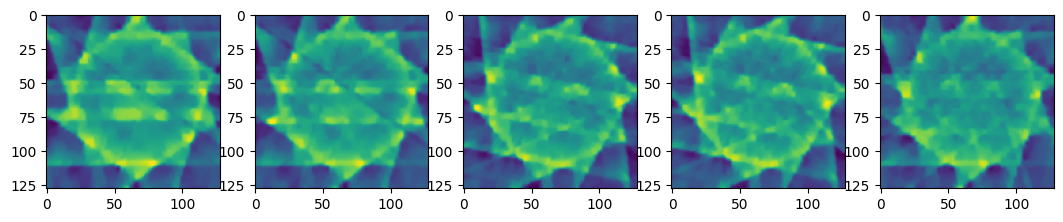

In [67]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow( sgks_recons[j]["x"].reshape((nx,ny)))

plt.show()

# Do S-GKS jointly

In [68]:
A = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in which_times ], voxel_shape)
b = np.hstack([ B[j] for j in which_times ] ) 
L = build_spatiotemporal_neumann2d(voxel_shape)


mm_gks_solver = MMGKS(A, L, b, noise_var=NOISE_VAR)

In [69]:
mm_sgks_data = mm_gks_solver.solve(n_iter=N_ITER, init_dim=5, weight_params=mm_weight_params)

130835.98825740365
25.444832295263218
28.85398679281414
30.83815830257149
32.31074169171558
33.46964063514134
34.30444479647294
34.91030635051861
35.40169383718628
35.8645625154963
36.25227441823889
36.588484536517726
36.87563480851245
37.13330040929692
37.33470308570688
37.521640418765735
37.68368075226467
37.8022402044431
37.902172166265046
37.97965161717109
38.048597659342164
38.12001266327372
38.16953502633484
38.212554076871065
38.23346915256157
38.243669442737826
38.26658110352243
38.300382232342805
38.34191876684614
38.37627302782055
38.42741436918451
38.475892329412325
38.53017337748057
38.57663495814494
38.62427913700673
38.67084414259062
38.704559710450326
38.72813061207235
38.755893574352775
38.78150557593218
38.79570381258649
38.808144255865024
38.82061663447898
38.82883511025278
38.83336690538978
38.836130678287745
38.838866097524445
38.84063494376562
38.84180877125965
38.843276068308064


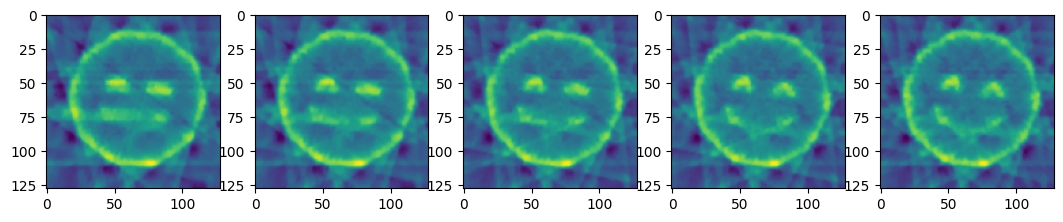

In [70]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(mm_sgks_data["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

In [71]:
ias_gks_solver = IASGKS(A, L, b, noise_var=NOISE_VAR)

ias_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}


In [72]:
ias_sgks_data = ias_gks_solver.solve(n_iter=N_ITER, init_dim=5, weight_params=ias_weight_params)

349641.4016479727


13350.25731776472
4080.604585647203
3540.198987806798
3866.1495466150827
4709.289201982398
5478.180615730469
5987.273557564615
6311.4540517257
6520.402796126044
6641.482313052434
6702.110373883361
6731.2828786831105
6735.180352604396
6724.791789097415
6715.784460736362
6715.286208414276
6722.663796591361
6732.478573197016
6742.743068263076
6752.538613754897
6761.622104977552
6770.325727556461
6781.470902532843
6789.9274921158
6783.399920975893
6761.474033887234
6743.045703433703
6738.032698567742
6738.712989804085
6740.3313877591
6741.7591678333865
6742.823898817057
6743.515352638428
6743.93552592875
6744.480387085886
6745.471585578111
6745.927028299546
6743.544306445499
6737.154251933595
6730.185090408973
6726.972184414993
6726.823025598043
6726.131861081263
6725.183470910523
6725.452201463123
6725.767802596769
6725.356909726253
6725.024294630107
6724.915101724403


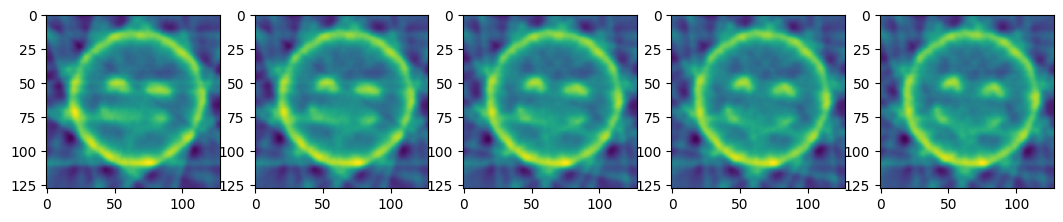

In [73]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(ias_sgks_data["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

# PS-GKS?

In [74]:
K = np.ones(A.shape[1])
K = K/np.linalg.norm(K)
K = jlinops.MatrixLinearOperator(K)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedVoxelGradPinvGPUOperator(voxel_shape, weights=w, tol=1e-4, *args, **kwargs)


mm_gks_solver = MMGKS(A, L, b, noise_var=NOISE_VAR, K=K, Lpinv_factory=Lpinv_factory)

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-5,
}

In [ ]:
mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=N_ITER, weight_params=mm_weight_params)

/home/jlindbloom/Github/IRLS_prec_GSBL/voxelgrad_testing/../msolver.py:923: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
21.04173273776393
25.784912769338813
30.12261734110832
32.72285406413556
34.39136554048289
35.82507955904163
35.867616425242204
35.992655358150834
36.43610077667837
36.85348978157441
37.19785458122275
37.314796110891095
37.51584203716158
37.732045208180956
37.8954227167663
38.00326602227491
38.152864939109165
38.231898282398745
38.308458881259305
38.40008585160813
38.4448021392137
38.52537655589129
38.57276468550006
38.61810117742476
38.66053371971258
38.706071735555156
38.74568454867553
38.775728620564934
38.79647810976917
38.828651780336365
38.85642799933957
38.87410464050113
38.88974596476976
38.90644798346732
38.93184406724426
38.937963185939594
38.9475431659677
38.96831033192135
38.97099961986951
38.98492823182938


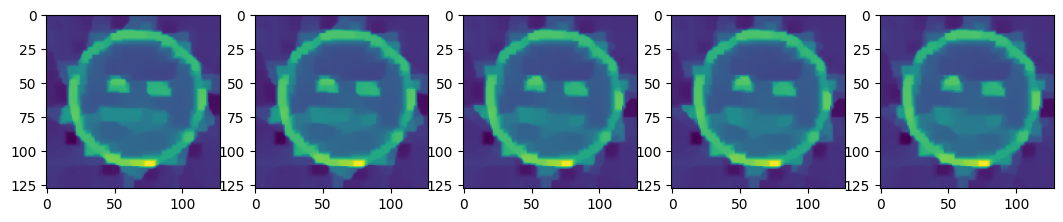

In [ ]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(mm_psgks_data["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

# Plot all?

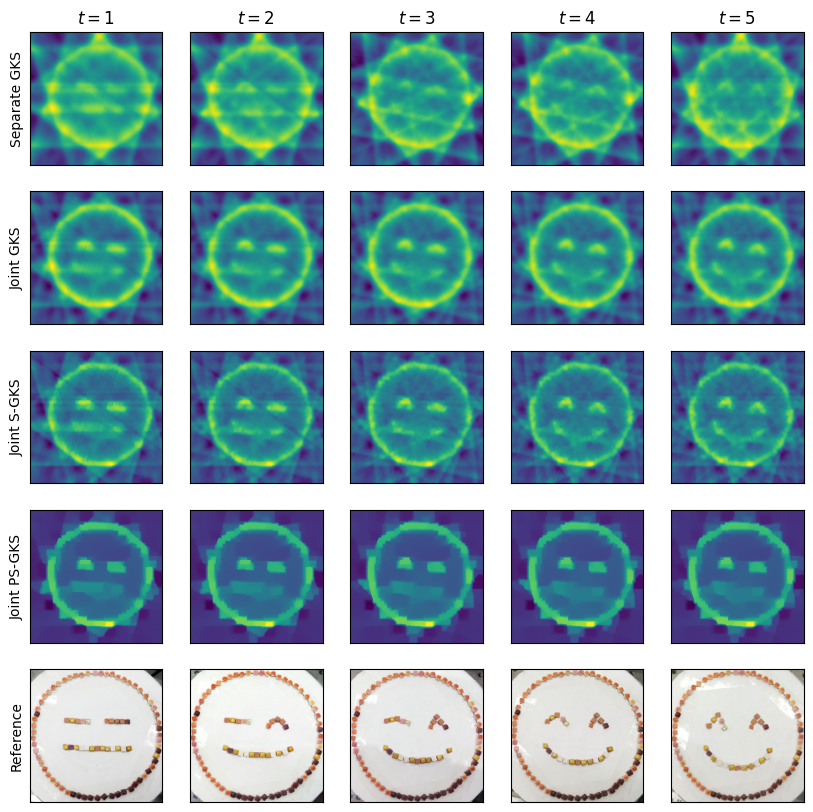

In [30]:
# Rows: individual L2, joint L2, joint S-GKS, joint PS-GKS
fig, axs = plt.subplots(5, 5, figsize=(10,10))

for j in range(5):
    axs[0,j].imshow( vgks_recons[j]["x"].reshape((nx,ny)))
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    axs[0,j].set_title(f"$t = {j+1}$")
axs[0,0].set_ylabel("Separate GKS")


for j in range(5):
    axs[1,j].imshow(vdata["x"].reshape((nx,ny,how_many))[:,:,j])
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
axs[1,0].set_ylabel("Joint GKS")


for j in range(5):
    axs[2,j].imshow(mm_sgks_data["x"].reshape((nx,ny,how_many))[:,:,j])
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
axs[2,0].set_ylabel("Joint S-GKS")


for j in range(5):
    axs[3,j].imshow(mm_psgks_data["x"].reshape((nx,ny,how_many))[:,:,j])
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
axs[3,0].set_ylabel("Joint PS-GKS")


for j in range(5):
    axs[4,j].imshow(photos[j])
    axs[4,j].set_xticks([])
    axs[4,j].set_yticks([])
axs[4,0].set_ylabel("Reference")



plt.show()